In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim


In [6]:
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

trainset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform_train
)
testset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_test
)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)


In [7]:
class PatchEmbedding(nn.Module):
    def __init__(self, img_size=32, patch_size=4, in_channels=3, embed_dim=128):
        super().__init__()
        self.patch_size = patch_size
        self.n_patches = (img_size // patch_size) ** 2

        self.proj = nn.Conv2d(
            in_channels, embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

    def forward(self, x):
        x = self.proj(x)               # (B, embed_dim, H/P, W/P)
        x = x.flatten(2)               # (B, embed_dim, N)
        x = x.transpose(1, 2)          # (B, N, embed_dim)
        return x


In [8]:
class VisionTransformer(nn.Module):
    def __init__(self,
                 img_size=32,
                 patch_size=4,
                 num_classes=10,
                 embed_dim=128,
                 num_heads=4,
                 num_layers=4,
                 mlp_dim=256,
                 dropout=0.1):
        super().__init__()

        self.patch_embed = PatchEmbedding(
            img_size, patch_size, 3, embed_dim
        )

        n_patches = self.patch_embed.n_patches

        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n_patches + 1, embed_dim))
        self.dropout = nn.Dropout(dropout)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers)

        self.norm = nn.LayerNorm(embed_dim)
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        B = x.size(0)

        x = self.patch_embed(x)

        cls_tokens = self.cls_token.expand(B, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)

        x = x + self.pos_embed
        x = self.dropout(x)

        x = self.encoder(x)

        x = self.norm(x)
        cls_output = x[:, 0]

        return self.fc(cls_output)


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = VisionTransformer().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.5)


In [10]:
epochs = 50

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    scheduler.step()

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Epoch [{epoch+1}/{epochs}]  Loss: {running_loss/len(trainloader):.4f}  Accuracy: {accuracy:.2f}%")

print("Training finished!")


Epoch [1/50]  Loss: 1.7653  Accuracy: 45.77%
Epoch [2/50]  Loss: 1.4359  Accuracy: 51.25%
Epoch [3/50]  Loss: 1.2796  Accuracy: 57.83%
Epoch [4/50]  Loss: 1.1811  Accuracy: 59.01%
Epoch [5/50]  Loss: 1.1179  Accuracy: 61.10%
Epoch [6/50]  Loss: 1.0725  Accuracy: 64.38%
Epoch [7/50]  Loss: 1.0363  Accuracy: 63.50%
Epoch [8/50]  Loss: 1.0075  Accuracy: 66.50%
Epoch [9/50]  Loss: 0.9853  Accuracy: 67.86%
Epoch [10/50]  Loss: 0.9600  Accuracy: 67.96%
Epoch [11/50]  Loss: 0.9356  Accuracy: 69.58%
Epoch [12/50]  Loss: 0.9159  Accuracy: 70.58%
Epoch [13/50]  Loss: 0.8990  Accuracy: 70.75%
Epoch [14/50]  Loss: 0.8886  Accuracy: 69.09%
Epoch [15/50]  Loss: 0.8731  Accuracy: 71.22%
Epoch [16/50]  Loss: 0.7646  Accuracy: 73.84%
Epoch [17/50]  Loss: 0.7411  Accuracy: 75.14%
Epoch [18/50]  Loss: 0.7259  Accuracy: 75.91%
Epoch [19/50]  Loss: 0.7127  Accuracy: 75.11%
Epoch [20/50]  Loss: 0.7041  Accuracy: 76.61%
Epoch [21/50]  Loss: 0.6915  Accuracy: 76.87%
Epoch [22/50]  Loss: 0.6851  Accuracy: 76.4

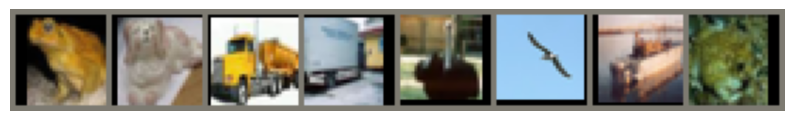

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def imshow(img):
    # Dénormalisation précise pour CIFAR-10
    mean = np.array([0.4914, 0.4822, 0.4465])
    std = np.array([0.2470, 0.2435, 0.2616])

    img = img.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1) 

    plt.figure(figsize=(10, 2))
    plt.imshow(img)
    plt.axis('off')
    plt.show()


try:
    dataiter = iter(trainloader)
    images, labels = next(dataiter)
    imshow(torchvision.utils.make_grid(images[:8]))
except NameError:
    print("Erreur : 'trainloader' n'est toujours pas défini. ")

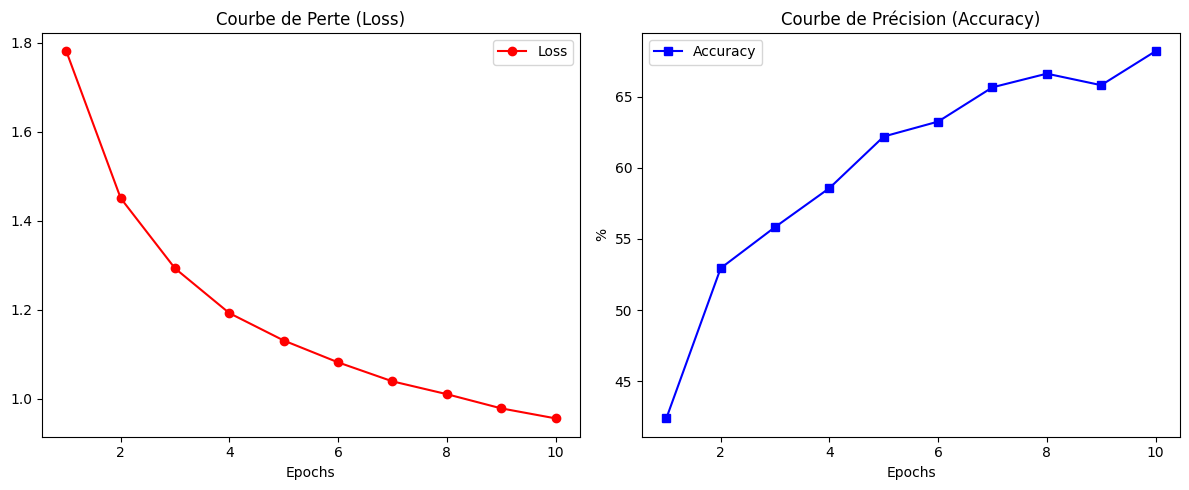

In [16]:
import matplotlib.pyplot as plt

history_loss = [1.7809, 1.4506, 1.2927, 1.1921, 1.1306, 1.0815, 1.0388, 1.0100, 0.9781, 0.9556]
history_acc = [42.38, 52.94, 55.83, 58.57, 62.20, 63.25, 65.66, 66.62, 65.81, 68.20]


epochs_range = range(1, len(history_loss) + 1)

plt.figure(figsize=(12, 5))

# Graphique de la Perte
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_loss, marker='o', color='red', label='Loss')
plt.title('Courbe de Perte (Loss)')
plt.xlabel('Epochs')
plt.legend()

# Graphique de l'Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_acc, marker='s', color='blue', label='Accuracy')
plt.title('Courbe de Précision (Accuracy)')
plt.xlabel('Epochs')
plt.ylabel('%')
plt.legend()

plt.tight_layout()
plt.show()